# Cohort-Level Forecast Bias and Explainability

Objectives:
1. Compare the static 5% churn baseline with observed outcomes.
2. Measure forecast bias across customer-array segments.
3. Compare Random Forest predictions against the baseline.
4. Identify segments with systematic optimism or pessimism.
5. Explain model predictions using SHAP.

Evaluation uses the fixed account-grouped test partition.
No model tuning will be performed using test results.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit

df = pd.read_csv(
    "../data/raw/Case_Study_2_CLV_Predictive_Analytics.csv"
)

scores = pd.read_csv(
    "../outputs/clv_scored_output.csv"
)

TARGET = "churn_event_next_12m"

labeled_df = df[df[TARGET].notna()].copy()

split1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=42
)

train_idx, temp_idx = next(
    split1.split(
        labeled_df,
        groups=labeled_df["account_id"]
    )
)

temp_df = labeled_df.iloc[temp_idx].copy()

split2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42
)

val_idx, test_idx = next(
    split2.split(
        temp_df,
        groups=temp_df["account_id"]
    )
)

test_df = temp_df.iloc[test_idx].copy()

analysis_df = test_df.merge(
    scores[
        [
            "array_id",
            "churn_probability_12m",
            "rf_churn_probability",
            "xgb_churn_probability"
        ]
    ],
    on="array_id",
    how="left",
    validate="one_to_one"
)

assert len(analysis_df) == 276
assert analysis_df["rf_churn_probability"].notna().all()

print("Analysis records:", len(analysis_df))
print("Unique accounts:", analysis_df["account_id"].nunique())
print("Observed churn:", round(analysis_df[TARGET].mean(), 4))

Analysis records: 276
Unique accounts: 150
Observed churn: 0.1341


In [3]:
train_df = labeled_df.iloc[train_idx].copy()

capacity_edges = train_df["current_capacity_tb"].quantile(
    [0, 1/3, 2/3, 1]
).to_numpy().copy()

capacity_edges[0] = -np.inf
capacity_edges[-1] = np.inf

analysis_df["capacity_segment"] = pd.cut(
    analysis_df["current_capacity_tb"],
    bins=capacity_edges,
    labels=["Low", "Medium", "High"],
    include_lowest=True
)

analysis_df["contract_end_year"] = pd.to_datetime(
    analysis_df["contract_end_date"]
).dt.year

print("Training-derived capacity boundaries:")
print(capacity_edges)

display(
    analysis_df[
        [
            "array_id",
            "capacity_segment",
            "expansion_potential_signal",
            "contract_end_year"
        ]
    ].head()
)

Training-derived capacity boundaries:
[         -inf  911.33333333 1716.33333333           inf]


,array_id,capacity_segment,expansion_potential_signal,contract_end_year
0,ARR_5007,Medium,Medium,2026
1,ARR_5023,Medium,High,2026
2,ARR_5025,High,Low,2026
3,ARR_5029,Medium,Low,2026
4,ARR_5031,Low,UNKNOWN,2026


In [4]:
def cohort_bias(data, group_column):
    result = (
        data.groupby(group_column, observed=True)
        .agg(
            arrays=("array_id", "count"),
            observed_churn=(TARGET, "mean"),
            selected_prediction=("churn_probability_12m", "mean"),
            rf_prediction=("rf_churn_probability", "mean")
        )
        .reset_index()
    )

    result["static_prediction"] = 0.05

    for name in ["static", "selected", "rf"]:
        result[f"{name}_bias_pp"] = (
            result[f"{name}_prediction"]
            - result["observed_churn"]
        ) * 100

    return result.round(4)


capacity_bias = cohort_bias(
    analysis_df, "capacity_segment"
)

expansion_bias = cohort_bias(
    analysis_df, "expansion_potential_signal"
)

contract_bias = cohort_bias(
    analysis_df, "contract_end_year"
)

print("CAPACITY COHORTS")
display(capacity_bias)

print("EXPANSION SIGNAL COHORTS")
display(expansion_bias)

print("CONTRACT YEAR COHORTS")
display(contract_bias)

CAPACITY COHORTS


,capacity_segment,arrays,observed_churn,selected_prediction,rf_prediction,static_prediction,static_bias_pp,selected_bias_pp,rf_bias_pp
0,Low,106,0.1415,0.1611,0.1730,0.05,-9.1509,1.9635,3.1510
1,Medium,93,0.1505,0.1611,0.1630,0.05,-10.0538,1.0607,1.2446
2,High,77,0.1039,0.1611,0.1574,0.05,-5.3896,5.7248,5.3467


EXPANSION SIGNAL COHORTS


,expansion_potential_signal,arrays,observed_churn,selected_prediction,rf_prediction,static_prediction,static_bias_pp,selected_bias_pp,rf_bias_pp
0,High,54,0.1481,0.1611,0.1529,0.05,-9.8148,1.2996,0.4742
1,Low,112,0.1071,0.1611,0.1604,0.05,-5.7143,5.4002,5.3252
2,Medium,97,0.1649,0.1611,0.1786,0.05,-11.4948,-0.3804,1.3642
3,UNKNOWN,13,0.0769,0.1611,0.1593,0.05,-2.6923,8.4222,8.2370


CONTRACT YEAR COHORTS


,contract_end_year,arrays,observed_churn,selected_prediction,rf_prediction,static_prediction,static_bias_pp,selected_bias_pp,rf_bias_pp
0,2026,22,0.2273,0.1611,0.1649,0.05,-17.7273,-6.6128,-6.2382
1,2027,103,0.0777,0.1611,0.1640,0.05,-2.7670,8.3475,8.6370
2,2028,110,0.1636,0.1611,0.1682,0.05,-11.3636,-0.2492,0.4556
3,2029,41,0.1463,0.1611,0.1607,0.05,-9.6341,1.4803,1.4380


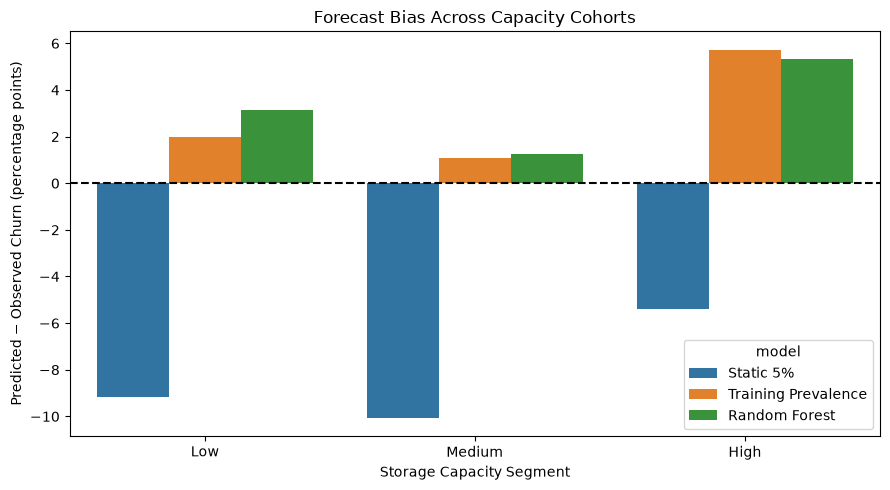

In [5]:
plot_df = capacity_bias.melt(
    id_vars="capacity_segment",
    value_vars=[
        "static_bias_pp",
        "selected_bias_pp",
        "rf_bias_pp"
    ],
    var_name="model",
    value_name="bias_pp"
)

plot_df["model"] = plot_df["model"].replace({
    "static_bias_pp": "Static 5%",
    "selected_bias_pp": "Training Prevalence",
    "rf_bias_pp": "Random Forest"
})

plt.figure(figsize=(9, 5))

sns.barplot(
    data=plot_df,
    x="capacity_segment",
    y="bias_pp",
    hue="model"
)

plt.axhline(0, color="black", linestyle="--")

plt.title("Forecast Bias Across Capacity Cohorts")
plt.xlabel("Storage Capacity Segment")
plt.ylabel("Predicted − Observed Churn (percentage points)")

plt.tight_layout()

plt.savefig(
    "../reports/figures/capacity_forecast_bias.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [6]:
from pathlib import Path

output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

capacity_bias.to_csv(
    output_dir / "capacity_cohort_bias.csv",
    index=False
)

expansion_bias.to_csv(
    output_dir / "expansion_cohort_bias.csv",
    index=False
)

contract_bias.to_csv(
    output_dir / "contract_cohort_bias.csv",
    index=False
)

print("Cohort bias tables exported.")

Cohort bias tables exported.


### Cohort-Level Forecast Bias — Key Findings

The static 5% churn assumption underestimated observed churn across all examined capacity, expansion-signal, and contract-year groups.

- **Capacity:** Medium-capacity arrays showed the greatest underestimation, at approximately 10.05 percentage points.
- **Expansion potential:** The Medium category showed the largest underestimation, at approximately 11.49 percentage points.
- **Contract year:** The 2026 contract cohort showed the largest underestimation, at approximately 17.73 percentage points, although this group contained only 22 arrays.

The training-prevalence approach generally reduced aggregate forecast bias but still overestimated or underestimated churn in individual segments.

These results suggest that the static assumption is poorly aligned with the supplied holdout outcomes. However, some cohorts are small, the observations within accounts are related, and the data does not support claims about long-term historical forecast drift.

The results should be treated as exploratory evidence rather than causal or statistically confirmed cohort effects.

## 5.5 — SHAP Explainability

SHAP is used to interpret the Random Forest comparator.

The Random Forest was trained on account-grouped training data
using the same regularized configuration selected earlier.

The training-prevalence baseline remains the selected probability
estimator because it achieved better Brier score and log loss.

SHAP interpretations are predictive associations, not causal effects.

In [7]:
import shap
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

FEATURES = [
    "current_capacity_tb",
    "utilization_rate_pct",
    "utilization_above_100_flag",
    "expansion_potential_signal"
]

# Reconstruct the features used during training
train_df["utilization_above_100_flag"] = (
    train_df["utilization_rate_pct"] > 1.0
).astype(int)

analysis_df["utilization_above_100_flag"] = (
    analysis_df["utilization_rate_pct"] > 1.0
).astype(int)

preprocessor = ColumnTransformer([
    (
        "numeric",
        SimpleImputer(strategy="median"),
        [
            "current_capacity_tb",
            "utilization_rate_pct",
            "utilization_above_100_flag"
        ]
    ),
    (
        "categorical",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]),
        ["expansion_potential_signal"]
    )
])

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200,
        max_depth=3,
        min_samples_leaf=20,
        random_state=42,
        n_jobs=-1
    ))
])

rf_pipeline.fit(
    train_df[FEATURES],
    train_df[TARGET].astype(int)
)

print("Random Forest reconstructed successfully.")

Random Forest reconstructed successfully.


In [8]:
X_explain = analysis_df[FEATURES]

rf_prob_check = rf_pipeline.predict_proba(X_explain)[:, 1]

max_difference = np.max(
    np.abs(
        rf_prob_check -
        analysis_df["rf_churn_probability"].to_numpy()
    )
)

print("Maximum prediction difference:", max_difference)

assert max_difference < 1e-6

print("PASS: Reconstructed model matches exported predictions.")

Maximum prediction difference: 1.942890293094024e-16
PASS: Reconstructed model matches exported predictions.


In [9]:
# Use the already-fitted preprocessing pipeline
X_transformed = rf_pipeline.named_steps[
    "preprocessor"
].transform(X_explain)

feature_names = rf_pipeline.named_steps[
    "preprocessor"
].get_feature_names_out()

rf_model = rf_pipeline.named_steps["model"]

explainer = shap.TreeExplainer(
    rf_model,
    model_output="raw"
)

shap_values = explainer.shap_values(X_transformed)

# Account for SHAP versions that return class-specific
# values as a list or a 3D array.
if isinstance(shap_values, list):
    shap_churn = shap_values[1]
elif np.asarray(shap_values).ndim == 3:
    shap_churn = shap_values[:, :, 1]
else:
    shap_churn = shap_values

print("SHAP shape:", shap_churn.shape)
print("Feature count:", len(feature_names))

SHAP shape: (276, 7)
Feature count: 7


In [10]:
expected = np.asarray(explainer.expected_value)

if expected.ndim == 0:
    expected_churn = float(expected)
else:
    expected_churn = float(expected[1])

reconstructed_prob = (
    expected_churn + shap_churn.sum(axis=1)
)

max_shap_error = np.max(
    np.abs(reconstructed_prob - rf_prob_check)
)

print("Maximum SHAP reconstruction error:", max_shap_error)

assert max_shap_error < 1e-5

print("PASS: SHAP values reconstruct RF churn probabilities.")

Maximum SHAP reconstruction error: 2.7755575615628914e-16
PASS: SHAP values reconstruct RF churn probabilities.


,feature,mean_abs_shap
0,numeric__current_capacity_tb,0.007867
1,numeric__utilization_rate_pct,0.007426
5,categorical__expansion_potential_signal_Medium,0.007404
3,categorical__expansion_potential_signal_High,0.002096
2,numeric__utilization_above_100_flag,0.001858
4,categorical__expansion_potential_signal_Low,0.000888
6,categorical__expansion_potential_signal_UNKNOWN,0.000838


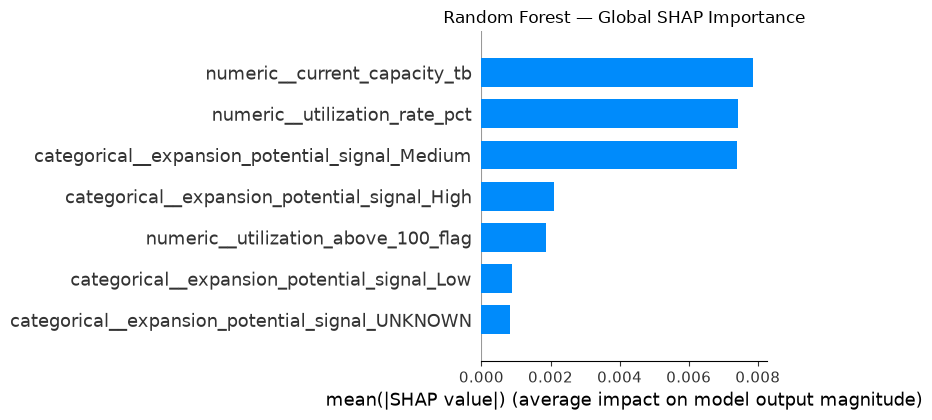

In [11]:
shap_importance = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": np.abs(shap_churn).mean(axis=0)
}).sort_values("mean_abs_shap", ascending=False)

display(shap_importance)

plt.figure(figsize=(9, 5))

shap.summary_plot(
    shap_churn,
    X_transformed,
    feature_names=feature_names,
    plot_type="bar",
    show=False
)

plt.title("Random Forest — Global SHAP Importance")
plt.tight_layout()

plt.savefig(
    "../reports/figures/shap_global_importance.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [12]:
# Select high, middle and low RF probability examples
order = np.argsort(rf_prob_check)

selected_positions = [
    int(order[0]),
    int(order[len(order) // 2]),
    int(order[-1])
]

for pos in selected_positions:
    print(
        "Array:", analysis_df.iloc[pos]["array_id"],
        "| RF churn probability:",
        round(float(rf_prob_check[pos]), 4)
    )

    local_contributions = pd.DataFrame({
        "Feature": feature_names,
        "SHAP contribution": shap_churn[pos]
    })

    display(
        local_contributions.reindex(
            local_contributions[
                "SHAP contribution"
            ].abs().sort_values(ascending=False).index
        )
    )

Array: ARR_6290 | RF churn probability: 0.1244


,Feature,SHAP contribution
0,numeric__current_capacity_tb,-0.010329
1,numeric__utilization_rate_pct,-0.009998
3,categorical__expansion_potential_signal_High,-0.008456
5,categorical__expansion_potential_signal_Medium,-0.005776
2,numeric__utilization_above_100_flag,-0.003349
6,categorical__expansion_potential_signal_UNKNOWN,0.000243
4,categorical__expansion_potential_signal_Low,-0.000043


Array: ARR_6995 | RF churn probability: 0.1624


,Feature,SHAP contribution
5,categorical__expansion_potential_signal_Medium,-0.003965
1,numeric__utilization_rate_pct,0.003771
3,categorical__expansion_potential_signal_High,-0.003445
2,numeric__utilization_above_100_flag,0.003074
4,categorical__expansion_potential_signal_Low,0.000530
6,categorical__expansion_potential_signal_UNKNOWN,0.000459
0,numeric__current_capacity_tb,-0.000041


Array: ARR_6489 | RF churn probability: 0.2487


,Feature,SHAP contribution
0,numeric__current_capacity_tb,0.071189
1,numeric__utilization_rate_pct,0.008425
2,numeric__utilization_above_100_flag,0.005744
5,categorical__expansion_potential_signal_Medium,-0.003123
3,categorical__expansion_potential_signal_High,0.002618
4,categorical__expansion_potential_signal_Low,0.000994
6,categorical__expansion_potential_signal_UNKNOWN,0.000784


In [13]:
from pathlib import Path

MODEL_VERSION = "v1_20261011"
SHAP_MODEL = "Random Forest Core"

shap_output = pd.DataFrame(
    shap_churn,
    columns=feature_names
)

shap_output.insert(
    0,
    "array_id",
    analysis_df["array_id"].to_numpy()
)

shap_output.insert(
    0,
    "account_id",
    analysis_df["account_id"].to_numpy()
)

shap_long = shap_output.melt(
    id_vars=["account_id", "array_id"],
    var_name="feature_name",
    value_name="shap_value"
)

shap_long["model_version"] = MODEL_VERSION
shap_long["model_name"] = SHAP_MODEL
shap_long["expected_probability"] = expected_churn

export_columns = [
    "account_id",
    "array_id",
    "model_version",
    "model_name",
    "feature_name",
    "shap_value",
    "expected_probability"
]

shap_long = shap_long[export_columns]

output_file = Path("../outputs/clv_shap_explanations.csv")

shap_long.to_csv(output_file, index=False)

print("SHAP records exported:", len(shap_long))
print("Features per array:", len(feature_names))
print("File:", output_file)

assert shap_long["shap_value"].notna().all()

SHAP records exported: 1932
Features per array: 7
File: ../outputs/clv_shap_explanations.csv
